# Ejercicio Módulo 3 - Aproximando la FIUBA con triángulos

**Inteligencia Artificial - CEIA - FIUBA**

**INSERTE AQUÍ SU NOMBRE**

En este ejercicio vamos a aproximar una foto de la Facultad de Ingeniería usando solamente **100 triángulos** semitransparentes. Cada triángulo tiene una posición, un color y una transparencia, y el objetivo es encontrar los valores que hacen que la imagen formada por los triángulos se parezca lo más posible a la foto.

Es un **problema de optimización**: no hay una solución exacta que tengamos que encontrar, sino una función de costo que queremos hacer lo más chica posible. Por eso es un buen problema para los algoritmos de búsqueda local.

### ¿Qué vamos a hacer en este ejercicio?

Primero vamos a ver todas las herramientas ya implementadas:

1. **Representación del problema**: cómo codificamos los triángulos.
2. **Función de costo**: cómo medimos qué tan parecida es la imagen a la foto.
3. **Generación de vecinos**: cómo modificamos un poco un estado.
4. **Gradiente descendente**: una primera búsqueda, que nos va a servir de referencia.

Luego, **tu desafío será implementar el algoritmo de Simulated Annealing** y comparar sus resultados con los de gradiente descendente.

In [1]:
# math lo vas a necesitar en Simulated Annealing
import math  # noqa: F401
import random

import matplotlib.pyplot as plt
import numpy as np
from PIL import Image, ImageDraw

random.seed(42)

# Tamaño de la imagen, en píxeles, y cantidad de triángulos
WIDTH, HEIGHT = 80, 60
N_TRIANGLES = 100

# Cantidad de iteraciones de cada búsqueda
MAX_STEPS = 100_000

## La imagen objetivo

La foto es de [Wikimedia Commons](https://commons.wikimedia.org/wiki/File:Facultad_de_Ingenier%C3%ADa_Universidad_de_Buenos_Aires_(FIUBA).jpg) (autor: Gobonobo, licencia [CC BY-SA 3.0](https://creativecommons.org/licenses/by-sa/3.0/)). La achicamos a 80 x 60 píxeles: con más píxeles la búsqueda es mucho más lenta, y para aproximarla con 100 triángulos no hace falta más detalle.

La guardamos como un array de numpy de 60 x 80 x 3: para cada píxel, la intensidad de rojo, verde y azul, entre 0 y 255.

Tamaño del array: (60, 80, 3)


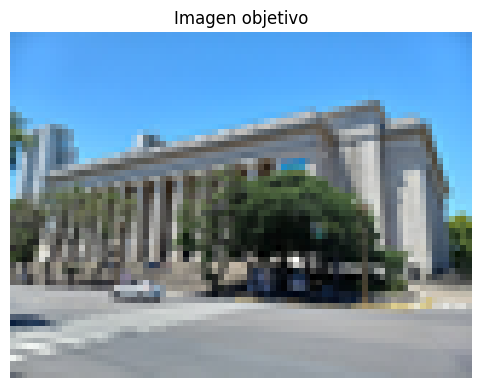

In [2]:
def load_target(path: str) -> np.ndarray:
    """
    Carga la imagen objetivo y la achica a WIDTH x HEIGHT píxeles.

    Args:
        path (str): Ruta de la imagen.

    Returns:
        np.ndarray: Array de HEIGHT x WIDTH x 3 con los colores de cada píxel.
    """
    image = Image.open(path).convert("RGB").resize((WIDTH, HEIGHT), Image.Resampling.LANCZOS)
    return np.asarray(image, dtype=np.int32)


def show_image(image: np.ndarray, title: str, ax=None) -> None:
    """Muestra una imagen, sin suavizar los píxeles."""
    ax = ax or plt.gca()
    ax.imshow(image.astype("uint8"), interpolation="nearest")
    ax.set_title(title)
    ax.axis("off")


target = load_target("fiuba.jpg")
print("Tamaño del array:", target.shape)

plt.figure(figsize=(6, 4.5))
show_image(target, "Imagen objetivo")
plt.show()

## Representación del problema

Cada triángulo es una lista de **10 números enteros**:

| Posición | Significado | Valores posibles |
|---|---|---|
| 0 a 5 | Coordenadas de los 3 vértices: `x1, y1, x2, y2, x3, y3` | `x` entre 0 y 79, `y` entre 0 y 59 |
| 6 a 8 | Color: rojo, verde y azul | entre 0 y 255 |
| 9 | Transparencia (*alpha*): 0 es invisible y 255 es opaco | entre 10 y 255 |

Un **estado** es una lista de 100 triángulos. Por ejemplo, este triángulo:

In [3]:
triangle = [10, 5, 70, 20, 30, 55, 200, 40, 40, 128]

Tiene sus vértices en `(10, 5)`, `(70, 20)` y `(30, 55)`, es rojo y es semitransparente. Definamos una función que genera un estado al azar:

In [4]:
# Posiciones dentro de cada triángulo donde empiezan el color y la transparencia
COLOR_START = 6
ALPHA_INDEX = 9


def random_triangle() -> list:
    """Genera un triángulo al azar: 3 vértices, un color y una transparencia."""
    vertices = []
    for _ in range(3):
        vertices += [random.randint(0, WIDTH - 1), random.randint(0, HEIGHT - 1)]
    color = [random.randint(0, 255) for _ in range(3)]
    return vertices + color + [random.randint(20, 120)]


def initialize_random_state() -> list:
    """
    Genera un estado al azar.

    Returns:
        list: Lista de N_TRIANGLES triángulos.
    """
    return [random_triangle() for _ in range(N_TRIANGLES)]

Para ver un estado, dibujamos los triángulos en orden sobre un fondo negro. Como son semitransparentes, donde se superponen los colores se mezclan:

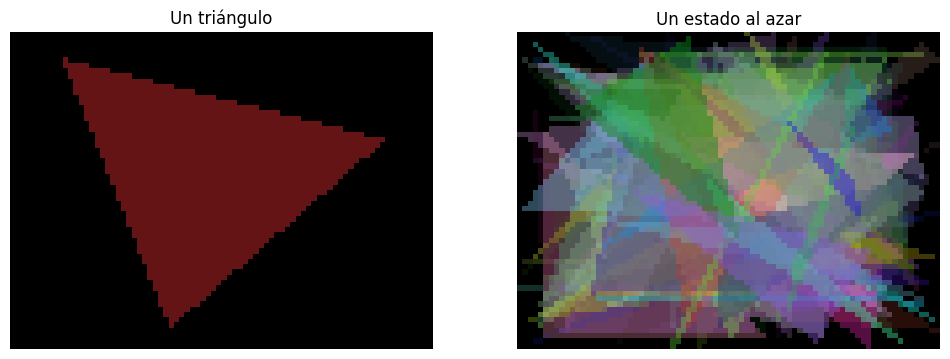

In [5]:
def render(state: list) -> np.ndarray:
    """
    Dibuja los triángulos de un estado, en orden, sobre un fondo negro.

    Args:
        state (list): Lista de triángulos.

    Returns:
        np.ndarray: Array de HEIGHT x WIDTH x 3 con la imagen.
    """
    image = Image.new("RGB", (WIDTH, HEIGHT), (0, 0, 0))
    draw = ImageDraw.Draw(image, "RGBA")
    for t in state:
        vertices = [(t[0], t[1]), (t[2], t[3]), (t[4], t[5])]
        draw.polygon(vertices, fill=tuple(t[COLOR_START:]))
    return np.asarray(image, dtype=np.int32)


random_state = initialize_random_state()

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
show_image(render([triangle]), "Un triángulo", axes[0])
show_image(render(random_state), "Un estado al azar", axes[1])
plt.show()

## Función de costo

Para medir qué tan parecida es la imagen de un estado a la foto, usamos el **error \
cuadrático medio**: para cada píxel y cada color, calculamos la diferencia entre la \
imagen y la foto, la elevamos al cuadrado y promediamos:

$$C(s) = \frac{1}{W \cdot H \cdot 3} \sum_{i=1}^{H} \sum_{j=1}^{W} \sum_{c=1}^{3} \left( \text{imagen}(s)_{ijc} - \text{foto}_{ijc} \right)^2$$

Queremos minimizar esta función. Si el costo fuera `0`, la imagen sería idéntica a \
la foto, algo imposible con solo 100 triángulos.

In [6]:
def cost(state: list, target: np.ndarray) -> float:
    """
    Calcula el error cuadrático medio entre la imagen del estado y la imagen objetivo.

    Args:
        state (list): Lista de triángulos.
        target (np.ndarray): Imagen objetivo.

    Returns:
        float: El costo del estado.
    """
    return float(np.mean((render(state) - target) ** 2))


print(f"Costo del estado al azar: {cost(random_state, target):.0f}")

Costo del estado al azar: 11268


## Generación de vecinos

Un **vecino** de un estado es el mismo estado con un solo número de un solo triángulo modificado un poco: un vértice se mueve unos píxeles, o un color o la transparencia cambian un poco.

Generar todos los vecinos de un estado para elegir el mejor es imposible: cada uno de los 1.000 números del estado se puede modificar de muchas formas, así que hay decenas de miles de vecinos, y calcular el costo de cada uno implica dibujar la imagen entera. Por eso vamos a generar **un vecino al azar** por vez:

In [7]:
def random_neighbor(state: list) -> list:
    """
    Genera un vecino al azar: modifica un poco un único número de un triángulo.

    Args:
        state (list): Lista de triángulos.

    Returns:
        list: Un nuevo estado. El estado original no se modifica.
    """
    neighbor = [t.copy() for t in state]
    t = random.choice(neighbor)
    k = random.randrange(10)

    if k < COLOR_START:
        # Movemos una coordenada de un vértice, sin salirnos de la imagen
        limit = WIDTH - 1 if k % 2 == 0 else HEIGHT - 1
        t[k] = min(limit, max(0, t[k] + random.randint(-8, 8)))
    elif k < ALPHA_INDEX:
        # Cambiamos un poco uno de los colores
        t[k] = min(255, max(0, t[k] + random.randint(-40, 40)))
    else:
        # Cambiamos un poco la transparencia, sin que el triángulo desaparezca
        t[k] = min(255, max(10, t[k] + random.randint(-30, 30)))

    return neighbor

Los vecinos se parecen muchísimo al estado original, y su costo cambia muy poco:

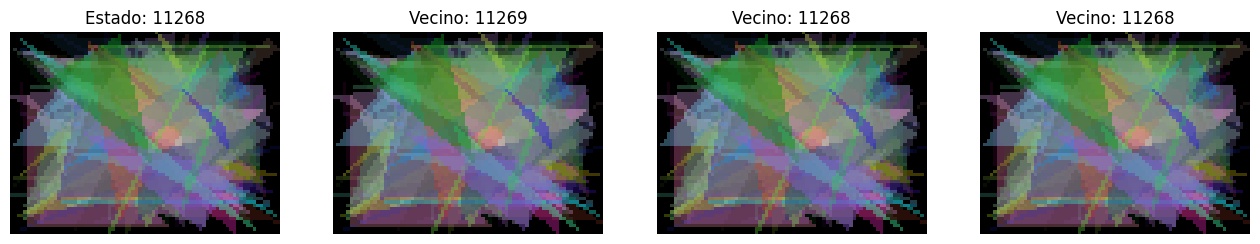

In [8]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.5))
show_image(render(random_state), f"Estado: {cost(random_state, target):.0f}", axes[0])
for ax in axes[1:]:
    neighbor = random_neighbor(random_state)
    show_image(render(neighbor), f"Vecino: {cost(neighbor, target):.0f}", ax)
plt.show()

¿Cuánto cambia el costo al pasar a un vecino? Lo medimos a partir de un estado ya bastante bueno, porque es ahí donde la búsqueda pasa la mayor parte del tiempo. Guardá estos valores, porque te van a servir más adelante:

In [9]:
def delta_scale(state: list, target: np.ndarray, samples: int = 500) -> None:
    """Muestra cuánto cambia el costo, en valor absoluto, al pasar a un vecino."""
    state_cost = cost(state, target)
    deltas = []
    for _ in range(samples):
        neighbor = random_neighbor(state)
        deltas.append(abs(cost(neighbor, target) - state_cost))

    print(f"Costo del estado: {state_cost:.0f}")
    print(f"Cambio típico del costo (mediana): {np.median(deltas):.2f}")
    print(f"Cambio grande (percentil 90): {np.percentile(deltas, 90):.2f}")

## Algoritmo de gradiente descendente

Como no podemos revisar todos los vecinos, usamos la variante de gradiente descendente **estocástica de primera opción** que vimos en la teoría: en cada paso generamos un vecino al azar, y nos movemos a él si no empeora el costo.

**Estructura general del algoritmo**

1. Generar un estado inicial aleatorio y calcular su costo.
2. Generar un vecino al azar y calcular su costo.
3. Si el vecino no es peor que el estado actual, moverse a él.
4. Repetir desde el paso 2 hasta llegar a `max_steps` iteraciones.

Además, guardamos el costo del estado actual en cada paso, para graficar después cómo fue bajando.

In [10]:
def grad_desc(target: np.ndarray, max_steps: int = MAX_STEPS) -> tuple:
    """
    Gradiente descendente estocástico de primera opción.

    Args:
        target (np.ndarray): Imagen objetivo.
        max_steps (int): Cantidad de iteraciones.

    Returns:
        tuple: (estado final, costo final, lista con el costo en cada paso)
    """
    current = initialize_random_state()
    current_cost = cost(current, target)
    history = [current_cost]

    for _ in range(max_steps):
        neighbor = random_neighbor(current)
        neighbor_cost = cost(neighbor, target)

        # Nos movemos si el vecino no es peor que el estado actual
        if neighbor_cost <= current_cost:
            current, current_cost = neighbor, neighbor_cost

        history.append(current_cost)

    return current, current_cost, history

Y una función para ver el resultado de una búsqueda: la foto, la imagen encontrada y cómo fue bajando el costo:

In [11]:
def plot_result(state: list, history: list, title: str) -> None:
    """Muestra la imagen objetivo, la imagen encontrada y la evolución del costo."""
    fig, axes = plt.subplots(1, 3, figsize=(16, 4))
    show_image(target, "Imagen objetivo", axes[0])
    show_image(render(state), f"{title}: {cost(state, target):.0f}", axes[1])
    axes[2].plot(history)
    axes[2].set_yscale("log")
    axes[2].set_xlabel("Iteración")
    axes[2].set_ylabel("Costo")
    axes[2].set_title("Evolución del costo")
    plt.tight_layout()
    plt.show()

Ejecutamos gradiente descendente 5 veces. Cada ejecución tarda alrededor de medio minuto:

In [12]:
grad_desc_results = []
for run in range(5):
    state, final_cost, history = grad_desc(target)
    grad_desc_results.append((final_cost, state, history))
    print(f"Ejecución {run + 1}: costo final {final_cost:.0f}")

grad_desc_mean = np.mean([result[0] for result in grad_desc_results])
print(f"\nCosto promedio de gradiente descendente: {grad_desc_mean:.0f}")

Ejecución 1: costo final 433


Ejecución 2: costo final 481


Ejecución 3: costo final 432


Ejecución 4: costo final 420


Ejecución 5: costo final 431

Costo promedio de gradiente descendente: 439


Veamos la mejor de las 5:

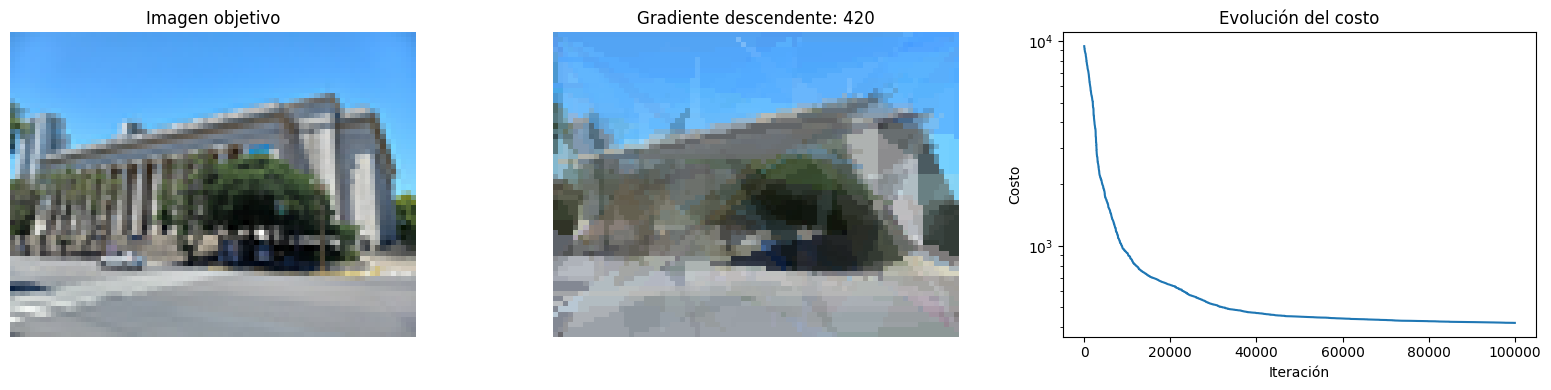

In [13]:
best_cost, best_state, best_history = min(grad_desc_results, key=lambda r: r[0])
plot_result(best_state, best_history, "Gradiente descendente")

La imagen ya tiene la forma general de la foto, pero fijate en la curva de costo: después de unas 40.000 iteraciones baja cada vez más despacio. Casi todos los cambios chicos empeoran la imagen, y gradiente descendente nunca acepta empeorar: queda atrapado cerca de un **mínimo local**, aunque haya otras configuraciones de triángulos mucho mejores.

Midamos cuánto cambia el costo al pasar a un vecino, partiendo de este estado:

In [14]:
delta_scale(best_state, target)

Costo del estado: 420
Cambio típico del costo (mediana): 0.48
Cambio grande (percentil 90): 7.23


## Simulated Annealing

Llegamos a la parte que **vos debés desarrollar**. Ahora te toca implementar el algoritmo de Simulated Annealing.

Para eso, debés completar la función que aparece más abajo.

> ⚠️ No modifiques los argumentos ni el tipo de salida: la función debe recibir exactamente los parámetros indicados y devolver el resultado especificado.

Antes de empezar, veamos dos herramientas para elegir los parámetros.

### Pista 1: la temperatura inicial

Recordemos que Simulated Annealing acepta un vecino peor con probabilidad $e^{-\Delta / T}$, donde $\Delta$ es cuánto empeora el costo. La temperatura se mide en **las mismas unidades que el costo**, así que lo que importa es cómo se compara con los cambios de costo que medimos arriba.

La siguiente función muestra, para varias temperaturas, con qué probabilidad se acepta un empeoramiento típico y uno grande:

In [15]:
def acceptance_table(temperatures: list, deltas: list) -> None:
    """
    Muestra la probabilidad de aceptar un vecino que empeora el costo en delta, para
    cada temperatura.
    """
    header = "Temperatura" + "".join(f" | Δ = {delta:<5}" for delta in deltas)
    print(header)
    print("-" * len(header))
    for temperature in temperatures:
        row = f"{temperature:>11}"
        for delta in deltas:
            row += f" | {math.exp(-delta / temperature):>9.1%}"
        print(row)


acceptance_table(temperatures=[0.01, 0.1, 1, 10, 100], deltas=[0.5, 7])

Temperatura | Δ = 0.5   | Δ = 7    
-----------------------------------
       0.01 |      0.0% |      0.0%
        0.1 |      0.7% |      0.0%
          1 |     60.7% |      0.1%
         10 |     95.1% |     49.7%
        100 |     99.5% |     93.2%


- Con una temperatura **muy alta**, el algoritmo acepta casi cualquier empeoramiento y se comporta como una búsqueda al azar: la imagen nunca se ordena.
- Con una temperatura **muy baja**, no acepta ningún empeoramiento y se comporta igual que gradiente descendente.

Una buena temperatura inicial es una con la que se aceptan con bastante frecuencia los empeoramientos típicos, pero no todos. Y al final de la búsqueda la temperatura tiene que ser tan baja que ya no se acepte casi ninguno.

### Pista 2: el `cooling_rate`

En cada paso, la temperatura se multiplica por `cooling_rate`, así que después de $k$ pasos vale:

$$T_k = T_0 \cdot \text{cooling\_rate}^{\,k}$$

Con 100.000 pasos, un `cooling_rate` que parece cercano a 1 enfría muchísimo. La siguiente función calcula la temperatura al final de la búsqueda:

In [16]:
def final_temperature(
    initial_temp: float, cooling_rate: float, max_steps: int = MAX_STEPS
) -> float:
    """Temperatura después de max_steps pasos de enfriamiento."""
    return initial_temp * cooling_rate**max_steps


for rate in [0.99, 0.999, 0.9999, 0.99999]:
    print(f"cooling_rate = {rate}: temperatura final {final_temperature(1, rate):.2e}")

cooling_rate = 0.99: temperatura final 0.00e+00
cooling_rate = 0.999: temperatura final 3.54e-44
cooling_rate = 0.9999: temperatura final 4.54e-05
cooling_rate = 0.99999: temperatura final 3.68e-01


Con `0.99` la temperatura llega prácticamente a cero en unos pocos cientos de pasos, y el resto de la búsqueda es igual a gradiente descendente. Si querés que la temperatura vaya de $T_0$ a una temperatura final $T_f$ justo en `max_steps` pasos, despejando de la fórmula de arriba:

$$\text{cooling\_rate} = \left( \frac{T_f}{T_0} \right)^{1 / \text{max\_steps}}$$

In [ ]:
def simulated_annealing(
    target: np.ndarray,
    initial_temp: float,
    cooling_rate: float,
    max_steps: int = MAX_STEPS,
) -> tuple:
    """
    Simulated Annealing para aproximar la imagen objetivo con triángulos.

    Args:
        target (np.ndarray): Imagen objetivo.
        initial_temp (float): Temperatura inicial.
        cooling_rate (float): Factor por el que se multiplica la temperatura en cada
                              paso.
        max_steps (int): Cantidad máxima de iteraciones.

    Returns:
        tuple: (estado final, costo final, lista con el costo en cada paso)
    """
    current = initialize_random_state()
    current_cost = cost(current, target)
    temperature = initial_temp  # noqa: F841
    history = [current_cost]

    #######################
    # TODO: Implementá aquí el algoritmo de Simulated Annealing.
    last_step = 0
    # Debés actualizar:
    # - current (para moverte a un nuevo estado)
    # - current_cost (según el nuevo estado)
    # - temperature (disminuirla con el tiempo)
    # - history (agregar el costo del estado actual en cada paso)
    # - last_step (número de iteraciones realizadas)
    #######################

    print(f"Iteraciones ejecutadas: {last_step}")
    print(f"Costo final: {current_cost:.0f}")

    return current, current_cost, history

Ejecutemos Simulated Annealing 5 veces:

In [ ]:
# Elegí los valores que quieras usar
initial_temp = ...
cooling_rate = ...

annealing_results = []
for run in range(5):
    print(f"Ejecución {run + 1}")
    state, final_cost, history = simulated_annealing(target, initial_temp, cooling_rate)
    annealing_results.append((final_cost, state, history))

annealing_mean = np.mean([result[0] for result in annealing_results])
print(f"\nCosto promedio de Simulated Annealing: {annealing_mean:.0f}")
print(f"Costo promedio de gradiente descendente: {grad_desc_mean:.0f}")

Veamos la mejor de las 5:

In [ ]:
best_cost, best_state, best_history = min(annealing_results, key=lambda r: r[0])
plot_result(best_state, best_history, "Simulated Annealing")

Respondé brevemente:

1. ¿Qué valores de `initial_temp` y `cooling_rate` usaste? ¿Por qué elegiste esos?

<<ESCRIBÍ AQUÍ>>

2. ¿Cómo se comparan los resultados de Simulated Annealing con los de gradiente descendente? ¿En qué se diferencian las curvas de costo de los dos algoritmos?

<<ESCRIBÍ AQUÍ>>